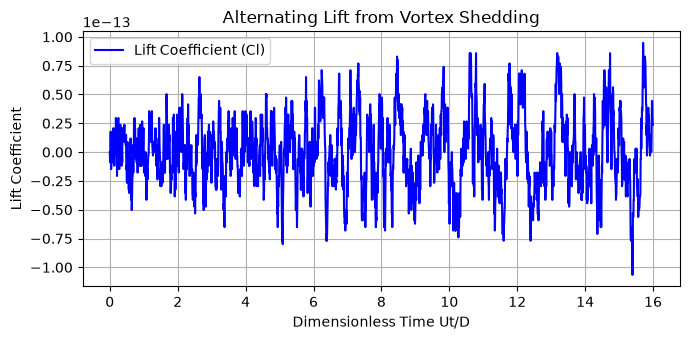

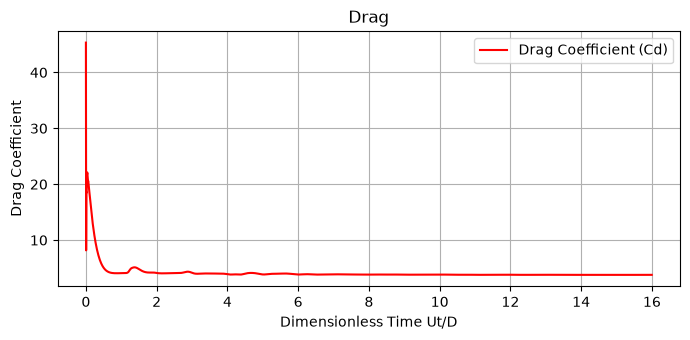

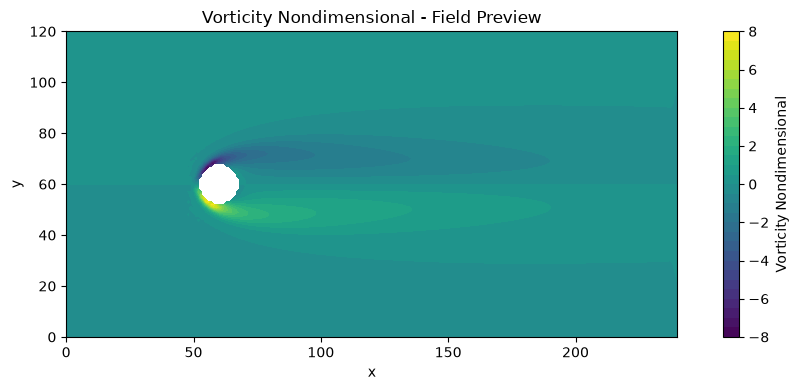

In [4]:
"""
===================================================================
  CFD & HT Lab - Experiment 4
  Topic: Karman Vortex Shedding over a Cylinder (D2Q9 LBM Solver)
  
  Student Name : Dev Pateliya
  Roll Number  : 23BME081
  Semester     : 7th Semester (B.Tech Mechanical Engineering)
===================================================================
"""

import numpy as np
import matplotlib.pyplot as plt

nx, ny = 241, 121
Re = 47.0
U_inlet = 0.10
D = 15.0
ic, jc = 60, 60
total_steps = 2400

w = np.array([4/9, 1/9, 1/9, 1/9, 1/9, 1/36, 1/36, 1/36, 1/36])
cx = np.array([0, 1, 0, -1, 0, 1, -1, -1, 1])
cy = np.array([0, 0, 1, 0, -1, 1, 1, -1, -1])

nu = (U_inlet * D) / Re
tau = 0.5 + 3.0 * nu

X, Y = np.meshgrid(np.arange(nx), np.arange(ny))
solid_mask = ((X - ic)**2 + (Y - jc)**2) <= (D / 2.0)**2

f = np.zeros((9, ny, nx))
for i in range(9):
    cu = 3.0 * (cx[i] * U_inlet)
    f[i] = w[i] * (1.0 + cu + 0.5 * (cu**2) - 1.5 * (U_inlet**2))

time_list = []
cl_history = []
cd_history = []

opp = [0, 3, 4, 1, 2, 7, 8, 5, 6]

for step in range(total_steps):
    rho = np.sum(f, axis=0)
    ux = np.sum(f * cx[:, None, None], axis=0) / rho
    uy = np.sum(f * cy[:, None, None], axis=0) / rho
    
    ux[solid_mask] = 0.0
    uy[solid_mask] = 0.0
    
    f_eq = np.zeros_like(f)
    u_sq = ux**2 + uy**2
    for i in range(9):
        cu = 3.0 * (cx[i] * ux + cy[i] * uy)
        f_eq[i] = w[i] * rho * (1.0 + cu + 0.5 * (cu**2) - 1.5 * u_sq)
        
    f_post = f - (1.0 / tau) * (f - f_eq)
    
    Fx, Fy = 0.0, 0.0
    for i in range(1, 9):
        next_x = X + cx[i]
        next_y = Y + cy[i]
        
        valid = (next_x >= 0) & (next_x < nx) & (next_y >= 0) & (next_y < ny)
        boundary_links = (~solid_mask) & valid & solid_mask[np.clip(next_y, 0, ny-1), np.clip(next_x, 0, nx-1)]
        
        Fx += np.sum(2.0 * f_post[i][boundary_links] * cx[i])
        Fy += np.sum(2.0 * f_post[i][boundary_links] * cy[i])
        
    cd = 2.0 * Fx / (1.0 * (U_inlet**2) * D)
    cl = 2.0 * Fy / (1.0 * (U_inlet**2) * D)
    
    f_stream = np.copy(f_post)
    for i in range(9):
        f_stream[i] = np.roll(f_post[i], shift=(cy[i], cx[i]), axis=(0, 1))
        
    for i in range(9):
        f_stream[i, solid_mask] = f_post[opp[i], solid_mask]
        
    for i in range(9):
        cu_in = 3.0 * (cx[i] * U_inlet)
        f_stream[i, :, 0] = w[i] * (1.0 + cu_in + 0.5 * (cu_in**2) - 1.5 * (U_inlet**2))
    f_stream[:, :, -1] = f_stream[:, :, -2]
    
    f = f_stream
    
    t_dim = (step * U_inlet) / D
    time_list.append(t_dim)
    cd_history.append(cd)
    cl_history.append(cl)

plt.figure(figsize=(7, 3.5))
plt.plot(time_list, cl_history, 'b-', label='Lift Coefficient (Cl)')
plt.xlabel('Dimensionless Time Ut/D')
plt.ylabel('Lift Coefficient')
plt.title('Alternating Lift from Vortex Shedding')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 3.5))
plt.plot(time_list, cd_history, 'r-', label='Drag Coefficient (Cd)')
plt.xlabel('Dimensionless Time Ut/D')
plt.ylabel('Drag Coefficient')
plt.title('Drag')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

du_dy = np.gradient(ux, axis=0)
dv_dx = np.gradient(uy, axis=1)
vorticity = (dv_dx - du_dy) * (D / U_inlet)
vorticity[solid_mask] = np.nan

plt.figure(figsize=(10, 4))
plt.contourf(X, Y, vorticity, levels=30, cmap='viridis')
plt.colorbar(label='Vorticity Nondimensional')
plt.title('Vorticity Nondimensional - Field Preview')
plt.xlabel('x')
plt.ylabel('y')
plt.gca().set_aspect('equal')
plt.tight_layout()
plt.show()